# Task 3 – Notebook 2: the four benchmark allocations
1. **Round-robin + equal power** – RB $n\to$ user $n \bmod 8$, $p_n=P_{\max}/16$.
2. **Strongest user + water-filling** – each RB to its best user, then $p_n=[L-1/a_n]^+$, $\sum p_n=P_{\max}$ (no QoS enforcement).
3. **MILP + equal power** – constants $r_{u,n}=B\log_2(1+\tfrac{P_{\max}}{16}a_{u,n})$; maximise $\sum r_{u,n}x_{u,n}$ s.t. one user per RB and $\sum_n r_{u,n}x_{u,n}\ge R_{\min}$ (SciPy `milp`, HiGHS). If infeasible it reports `qos_feasible=False` and returns the best effort (most users satisfied, then sum rate).
4. **MILP assignment + KKT water-filling** – fixed assignment, Lagrangian $\sum_u(1+\mu_u)R_u-\nu(\sum p-P_{\max})$. Stationarity on RB $n$ of user $u$ gives $p_n=[L_u-1/a_n]^+$ with $L_u=(1+\mu_u)B/(\nu\ln2)$. If user $u$'s QoS is slack, $\mu_u=0$ and $L_u=L$; if it is active, $L_u=\lambda_u$, the level that gives exactly $R_{\min}$. Hence $L_u=\max(L,\lambda_u)$ and the scalar $L$ is found by bisection so that $\sum p_n=P_{\max}$. If $\sum_u P_u^{\min}>P_{\max}$ the assignment cannot meet QoS: Rmin is guaranteed to the cheapest users that fit and the case is flagged.

In [1]:
import os, sys
from pathlib import Path
ROOT = Path.cwd().resolve().parents[1]
os.chdir(ROOT); sys.path.insert(0, str(ROOT))
import numpy as np, pandas as pd, matplotlib.pyplot as plt, torch
torch.set_num_threads(1)
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 30)
from task3_resource.system import P, dbm_to_w, draw_channels, rb_rates, user_rates, POWER_DBM_GRID
from task3_resource import allocation as al, dnn, experiments as ex
T = ex.RES / "tables"; F = ex.RES / "figures"


In [2]:
pdbm = 30; pmax = dbm_to_w(pdbm)
a = draw_channels(1, np.random.default_rng(1))[0]
milp_res = al.milp_equal_power(a, pmax)
runs = {"1 Round-robin": al.round_robin(a, pmax), "2 Strongest+WF": al.strongest_user_wf(a, pmax), "3 MILP+equal": milp_res,
        "4 MILP+KKT-WF": al.milp_then_waterfilling(a, pmax, milp_result=milp_res)}
tab = []
for name, (x, pw, info) in runs.items():
    R = user_rates(x, pw, a)/1e6
    tab.append({"method": name, "sum rate [Mbps]": R.sum(), "users >= 1 Mbps": int((R >= 1).sum()), "min user rate": R.min(),
                "power used / budget": pw.sum()/pmax, "QoS feasible flag": info.get("qos_feasible", "n/a"), "RB owner": x.argmax(0).tolist()})
pd.DataFrame(tab).round(3)

,method,sum rate [Mbps],users >= 1 Mbps,min user rate,power used / budget,QoS feasible flag,RB owner
0,1 Round-robin,15.732,8,1.154,1.0,n/a,"[0, 1, 2, 3, 4, 5, 6, 7, 0, 1, 2, 3, 4, 5, 6, 7]"
1,2 Strongest+WF,27.032,3,0.000,1.0,n/a,"[4, 2, 4, 2, 4, 4, 2, 2, 2, 2, 2, 5, 2, 4, 4, 4]"
2,3 MILP+equal,23.129,8,1.067,1.0,True,"[4, 3, 4, 2, 6, 1, 1, 2, 2, 3, 2, 5, 2, 7, 0, 4]"
3,4 MILP+KKT-WF,23.129,8,1.066,1.0,True,"[4, 3, 4, 2, 6, 1, 1, 2, 2, 3, 2, 5, 2, 7, 0, 4]"


In [3]:
x, pw, _ = runs["4 MILP+KKT-WF"]
print("user rates [Mbps]:", (user_rates(x, pw, a)/1e6).round(2))
print("power per RB [mW]:", (pw*1e3).round(1))

user rates [Mbps]: [1.36 1.7  9.14 1.73 5.47 1.36 1.31 1.07]
power per RB [mW]: [63.2 61.5 63.2 63.2 62.8 60.6 61.1 63.2 63.2 60.4 63.2 62.9 63.2 62.2
 62.9 63.2]


### Benchmark curves (methods 1–4, 300 drops per power) and MILP feasibility
Produced by `python experiments/run_task3.py` (see notebook 5 for all six methods).

,power_dbm,method,sum_rate_mbps,qos_pct,all_users_qos_pct,jain,p5_user_rate_mbps,time_ms
0,15.0,1 Round-robin + equal power,7.817,38.375,0.000,0.580,0.034,0.015
1,15.0,2 Strongest user + water-filling,21.379,27.458,0.000,0.215,0.000,0.383
2,15.0,3 MILP + equal power,13.083,78.083,7.667,0.514,0.000,22.569
3,15.0,4 MILP + KKT water-filling,13.154,78.125,8.000,0.507,0.000,28.046
20,20.0,1 Round-robin + equal power,11.062,53.917,0.333,0.663,0.098,0.014
21,20.0,2 Strongest user + water-filling,26.097,30.292,0.000,0.217,0.000,0.350
22,20.0,3 MILP + equal power,16.462,90.500,39.000,0.535,0.000,18.358
23,20.0,4 MILP + KKT water-filling,16.512,90.500,39.000,0.530,0.000,23.668
40,25.0,1 Round-robin + equal power,14.864,71.167,6.333,0.739,0.245,0.012
41,25.0,2 Strongest user + water-filling,30.859,31.958,0.000,0.218,0.000,0.321


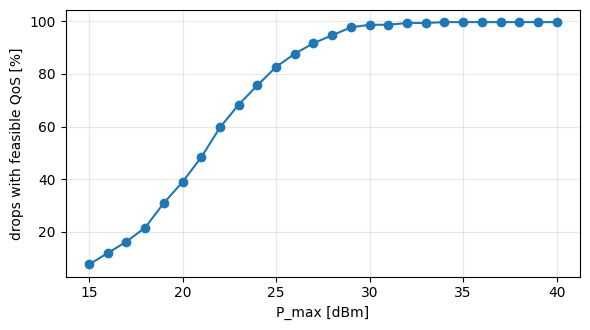

In [4]:
bench = pd.read_csv(T / "task3_benchmark_results.csv")
display(bench[bench.power_dbm.isin([15, 20, 25, 30, 40])][["power_dbm", "method", "sum_rate_mbps", "qos_pct", "all_users_qos_pct", "jain", "p5_user_rate_mbps", "time_ms"]].round(3))
feas = pd.read_csv(T / "task3_milp_feasibility.csv")
fig, ax = plt.subplots(figsize=(6, 3.4)); ax.plot(feas.power_dbm, feas.milp_qos_feasible_pct, "o-")
ax.set_xlabel("P_max [dBm]"); ax.set_ylabel("drops with feasible QoS [%]"); ax.grid(alpha=.3); fig.tight_layout()
fig.savefig(F / "milp_qos_feasibility_vs_power.png", dpi=150); plt.show()